## 1. Install/import libraries

In [1]:
!pip -q install scikit-learn seaborn

import os, random, hashlib, json, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, roc_curve, f1_score,
    precision_recall_fscore_support
)
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import layers, regularizers, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("Python:", platform.python_version())
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

Python: 3.13.16
TensorFlow: 2.21.0
GPU devices: []


## 2. Mount Google Drive and locate the dataset
Download the Kaggle ZIP, upload it to Drive, and extract it. Set `DATASET_DIR` to the extracted directory that contains the class folders.

In [6]:
from pathlib import Path

DATASET_DIR = Path("/content/mpox_dataset")

print("Folder exists:", DATASET_DIR.exists())

for item in DATASET_DIR.iterdir():
    print(item.name)

Folder exists: True
Augmented Images
Fold1
Original Images
Monkeypox_Dataset_metadata.csv


In [4]:
from google.colab import files

uploaded = files.upload()

Saving Monkeypox.zip to Monkeypox.zip


In [5]:
import zipfile
from pathlib import Path

ZIP_PATH = next(
    name for name in uploaded
    if name.lower().endswith(".zip")
)

EXTRACT_DIR = Path("/content/mpox_dataset")
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

print("Dataset extracted successfully! ❤️")
print("Location:", EXTRACT_DIR)

for item in EXTRACT_DIR.iterdir():
    print("📁" if item.is_dir() else "📄", item.name)

Dataset extracted successfully! ❤️
Location: /content/mpox_dataset
📁 Augmented Images
📁 Fold1
📁 Original Images
📄 Monkeypox_Dataset_metadata.csv


In [7]:
from pathlib import Path

EXTRACT_DIR = Path("/content/mpox_dataset")

for p in EXTRACT_DIR.rglob("*"):
    if p.is_dir():
        print("📁", p)

📁 /content/mpox_dataset/Augmented Images
📁 /content/mpox_dataset/Fold1
📁 /content/mpox_dataset/Original Images
📁 /content/mpox_dataset/Augmented Images/Augmented Images
📁 /content/mpox_dataset/Fold1/Fold1
📁 /content/mpox_dataset/Original Images/Original Images
📁 /content/mpox_dataset/Original Images/Original Images/Monkey Pox
📁 /content/mpox_dataset/Original Images/Original Images/Others
📁 /content/mpox_dataset/Fold1/Fold1/Fold1
📁 /content/mpox_dataset/Fold1/Fold1/Fold1/Val
📁 /content/mpox_dataset/Fold1/Fold1/Fold1/Train
📁 /content/mpox_dataset/Fold1/Fold1/Fold1/Test
📁 /content/mpox_dataset/Fold1/Fold1/Fold1/Val/Monkeypox
📁 /content/mpox_dataset/Fold1/Fold1/Fold1/Val/Others
📁 /content/mpox_dataset/Fold1/Fold1/Fold1/Train/Monkeypox
📁 /content/mpox_dataset/Fold1/Fold1/Fold1/Train/Others
📁 /content/mpox_dataset/Fold1/Fold1/Fold1/Test/Monkeypox
📁 /content/mpox_dataset/Fold1/Fold1/Fold1/Test/Others
📁 /content/mpox_dataset/Augmented Images/Augmented Images/Monkeypox_augmented
📁 /content/mpox

In [8]:
from pathlib import Path

DATASET_DIR = Path(
    "/content/mpox_dataset/Original Images/Original Images"
)

print("Folder exists:", DATASET_DIR.exists())

for folder in DATASET_DIR.iterdir():
    print(folder.name, "->", len(list(folder.iterdir())), "items")

Folder exists: True
Monkey Pox -> 102 items
Others -> 126 items


In [9]:
import pandas as pd

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

CLASS_FOLDERS = {
    "Monkey Pox": "Mpox",
    "Others": "Others"
}

records = []

for folder_name, label in CLASS_FOLDERS.items():
    folder = DATASET_DIR / folder_name

    if not folder.exists():
        print("Folder missing:", folder)
        continue

    for path in folder.rglob("*"):
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
            records.append({
                "path": str(path),
                "label": label
            })

df = pd.DataFrame(records)

print("Total original images:", len(df))
print("\nImages per class:")
print(df["label"].value_counts())

if df.empty:
    raise ValueError("No images found. Check the folder path.")

Total original images: 228

Images per class:
label
Others    126
Mpox      102
Name: count, dtype: int64


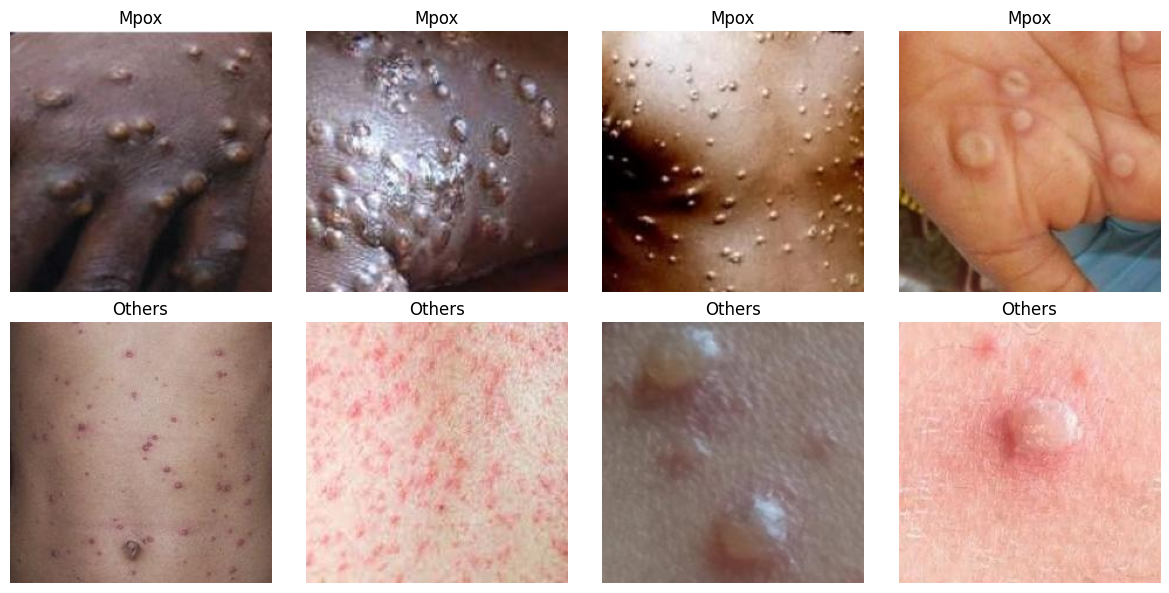

In [10]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for row, label in enumerate(["Mpox", "Others"]):
    samples = df[df["label"] == label].sample(
        n=min(4, (df["label"] == label).sum()),
        random_state=42
    )

    for col, (_, record) in enumerate(samples.iterrows()):
        img = Image.open(record["path"]).convert("RGB")
        axes[row, col].imshow(img)
        axes[row, col].set_title(label)
        axes[row, col].axis("off")

    for col in range(len(samples), 4):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [11]:
import hashlib
from sklearn.model_selection import train_test_split

SEED = 42

def sha256_file(filepath):
    h = hashlib.sha256()
    with open(filepath, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

# Find exact duplicate files
df["sha256"] = df["path"].apply(sha256_file)

print("Images before duplicate removal:", len(df))
print("Duplicate files:", df.duplicated("sha256").sum())

# Stop if identical files have conflicting labels
conflicts = df.groupby("sha256")["label"].nunique()
if (conflicts > 1).any():
    raise ValueError("Identical files have conflicting labels. Investigate first.")

df = df.drop_duplicates("sha256").reset_index(drop=True)

# Convert class labels to numbers
df["label_id"] = df["label"].map({
    "Mpox": 0,
    "Others": 1
})

# 70% train, 15% validation, 15% test
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label_id"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label_id"],
    random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("\nTrain images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("\nTraining class counts:")
print(train_df["label"].value_counts())

print("\nValidation class counts:")
print(val_df["label"].value_counts())

print("\nTest class counts:")
print(test_df["label"].value_counts())

# Confirm that exact duplicate images do not cross splits
assert set(train_df["sha256"]).isdisjoint(set(val_df["sha256"]))
assert set(train_df["sha256"]).isdisjoint(set(test_df["sha256"]))
assert set(val_df["sha256"]).isdisjoint(set(test_df["sha256"]))

print("\n✅ Exact-duplicate leakage checks passed!")

Images before duplicate removal: 228
Duplicate files: 1

Train images: 158
Validation images: 34
Test images: 35

Training class counts:
label
Others    87
Mpox      71
Name: count, dtype: int64

Validation class counts:
label
Others    19
Mpox      15
Name: count, dtype: int64

Test class counts:
label
Others    19
Mpox      16
Name: count, dtype: int64

✅ Exact-duplicate leakage checks passed!


In [12]:
import tensorflow as tf
import numpy as np
from tensorflow.keras import layers
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

tf.keras.utils.set_random_seed(SEED)

def load_image(path, label):
    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)

    return image, tf.cast(label, tf.float32)


def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        frame["path"].values,
        frame["label_id"].values.astype("int32")
    ))

    if training:
        ds = ds.shuffle(
            len(frame),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Training batches: 10
Validation batches: 3
Test batches: 3


In [13]:
from tensorflow.keras import Model, regularizers
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

# Augmentation happens only during training
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.04)(x)
x = layers.RandomZoom(0.08)(x)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid",
    kernel_regularizer=regularizers.l2(1e-4)
)(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [14]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        "best_mpox_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 622ms/step - accuracy: 0.5766 - loss: 0.7736
Epoch 1: val_loss improved from None to 0.69394, saving model to best_mpox_model.keras

Epoch 1: finished saving model to best_mpox_model.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.5949 - loss: 0.7490 - val_accuracy: 0.5882 - val_loss: 0.6939 - learning_rate: 0.0010
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 748ms/step - accuracy: 0.6763 - loss: 0.5949
Epoch 2: val_loss improved from 0.69394 to 0.59692, saving model to best_mpox_model.keras

Epoch 2: finished saving model to best_mpox_model.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 10s 953ms/step - accuracy: 0.6582 - loss: 0.6643 - val_accuracy: 0.6471 - val_loss: 0.5969 - learning_rate: 0.0010
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 862ms/step - accuracy: 0.7062 - loss: 0.5512
Epoch 3: val_loss improved from 0.59692 to 0.55770, saving model to best_mpox_model.keras

Epoch 3: finished saving model to best_mpox_model.keras
10/10 ━━━━━━━━━━━━━━━━━

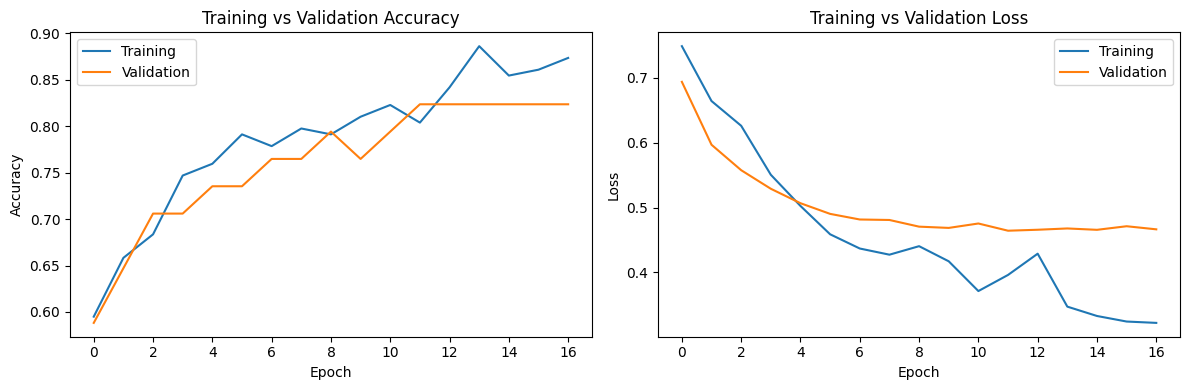

In [15]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Training vs Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Training vs Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

In [16]:
import numpy as np
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)
import seaborn as sns
import matplotlib.pyplot as plt

# Predict probabilities
y_true = np.concatenate([
    labels.numpy().reshape(-1)
    for _, labels in test_ds
]).astype(int)

probabilities = model.predict(test_ds, verbose=0).reshape(-1)

# Class 0 = Mpox; Class 1 = Others
y_pred = (probabilities >= 0.5).astype(int)

print("TEST ACCURACY:", round(accuracy_score(y_true, y_pred), 4))
print("MACRO F1:", round(
    f1_score(y_true, y_pred, average="macro", zero_division=0), 4
))

print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Mpox", "Others"],
    digits=4,
    zero_division=0
))

if len(np.unique(y_true)) == 2:
    auc = roc_auc_score(
        (y_true == 0).astype(int),
        1 - probabilities
    )
    print("ROC-AUC (Mpox positive):", round(auc, 4))

TEST ACCURACY: 0.8286
MACRO F1: 0.825

Classification Report:

              precision    recall  f1-score   support

        Mpox     0.8571    0.7500    0.8000        16
      Others     0.8095    0.8947    0.8500        19

    accuracy                         0.8286        35
   macro avg     0.8333    0.8224    0.8250        35
weighted avg     0.8313    0.8286    0.8271        35

ROC-AUC (Mpox positive): 0.8125


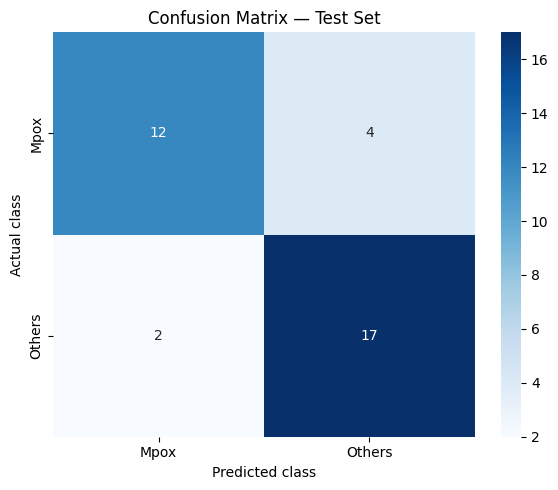

In [17]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Mpox", "Others"],
    yticklabels=["Mpox", "Others"]
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Confusion Matrix — Test Set")
plt.tight_layout()
plt.show()

Misclassified images: 6


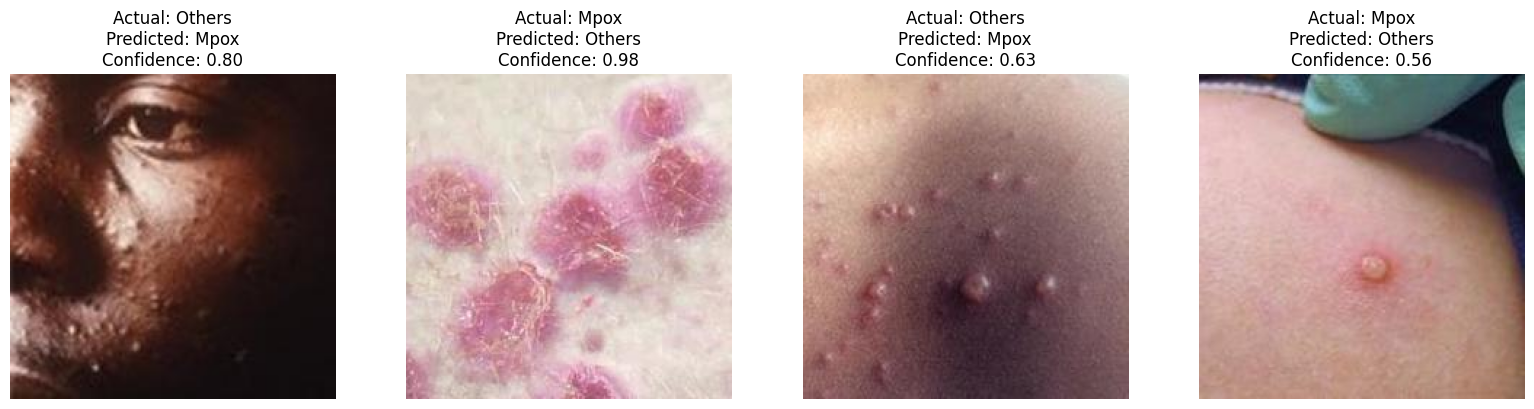

In [18]:
from PIL import Image

errors = np.where(y_true != y_pred)[0]

print("Misclassified images:", len(errors))

if len(errors) == 0:
    print("No test errors found. Do not invent errors for the report.")
else:
    selected = errors[:4]

    fig, axes = plt.subplots(
        1, len(selected),
        figsize=(4 * len(selected), 4)
    )

    if len(selected) == 1:
        axes = [axes]

    for ax, idx in zip(axes, selected):
        row = test_df.iloc[idx]
        img = Image.open(row["path"]).convert("RGB")

        actual = "Mpox" if y_true[idx] == 0 else "Others"
        predicted = "Mpox" if y_pred[idx] == 0 else "Others"
        confidence = 1 - probabilities[idx] if y_pred[idx] == 0 else probabilities[idx]

        ax.imshow(img)
        ax.set_title(
            f"Actual: {actual}\nPredicted: {predicted}\n"
            f"Confidence: {confidence:.2f}"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [19]:
print("TEST RESULTS")
print("-" * 35)
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Macro F1:", round(
    f1_score(y_true, y_pred, average="macro", zero_division=0), 4
))
print("Misclassified images:", len(errors))
print("\nPer-class report:")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=["Mpox", "Others"],
    zero_division=0
))

TEST RESULTS
-----------------------------------
Accuracy: 0.8286
Macro F1: 0.825
Misclassified images: 6

Per-class report:
              precision    recall  f1-score   support

        Mpox       0.86      0.75      0.80        16
      Others       0.81      0.89      0.85        19

    accuracy                           0.83        35
   macro avg       0.83      0.82      0.82        35
weighted avg       0.83      0.83      0.83        35



In [20]:
import json

model.save("/content/mpox_classifier.keras")

test_results = {
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "macro_f1": float(
        f1_score(y_true, y_pred, average="macro", zero_division=0)
    ),
    "misclassified_images": int(len(errors)),
    "train_images": int(len(train_df)),
    "validation_images": int(len(val_df)),
    "test_images": int(len(test_df))
}

with open("/content/test_results.json", "w") as f:
    json.dump(test_results, f, indent=2)

print("Model and results saved successfully! ❤️")

Model and results saved successfully! ❤️


In [21]:
from google.colab import files

files.download("/content/mpox_classifier.keras")
files.download("/content/test_results.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>